In [29]:
%load_ext autoreload
%autoreload 2

import anndata as ad
adata = ad.read_h5ad("./data/larry/larry_processed.h5ad")
adata_cospar = ad.read_h5ad("./data/larry/cospar_tmap_result.h5ad")
print(adata)
print(adata_cospar)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
AnnData object with n_obs × n_vars = 49302 × 2000
    obs: 'Library', 'Cell barcode', 'time_info', 'Starting population', 'state_info', 'Well', 'SPRING-x', 'SPRING-y', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'velocity_gamma', 'velocity_qreg_ratio', 'velocity_r2', 'velocity_genes'
    uns: 'data_des', 'log1p', 'neighbors', 'pca', 'state_info_colors', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_clone', 'X_emb', 'X_pca', 'X_spring', 'velocity_spring'
    varm: 'PCs'
    layers: 'Ms', 'Mu', 'ambiguous', 'matrix', 'spliced', 'unspliced', 'variance_velocity', 'velocity'
    obsp: 'connectivities', 'distances'
AnnData object with n_obs × n_vars = 49116 × 25289
    obs: 'time

In [30]:
import numpy as np

def match_by_X_emb(adata, adata_cospar):
    X1 = adata.obsm["X_emb"]
    X2 = adata_cospar.obsm["X_emb"]

    # Convert rows to tuples (hashable, exact float match)
    rows1 = [tuple(r) for r in X1]
    rows2 = [tuple(r) for r in X2]

    # Build lookup: embedding -> index in adata_cospar
    lookup = {row: j for j, row in enumerate(rows2)}

    # Map each row in adata → adata_cospar index (or -1 if missing)
    mapA2B = np.array([lookup.get(row, -1) for row in rows1], dtype=int)

    return mapA2B

mapA2B = match_by_X_emb(adata, adata_cospar)
print("Matched:", np.sum(mapA2B != -1), "/", len(mapA2B))

Matched: 49111 / 49302


In [31]:
from scipy.spatial import cKDTree
import joblib

# ===============================================================
# 0. Load embedder
# ===============================================================
emb = joblib.load("./data/larry/larry_embedder.pkl")
emb.gene_names = adata.var_names
emb.cospar_index = mapA2B     # your mapping (adata → adata_cospar)


# ===============================================================
# 1. Tentatively assign new_X_emb from FlowMap
# ===============================================================
n_cospar = adata_cospar.n_obs
new_X_emb = np.full((n_cospar, 2), np.nan)   # initialize with NaNs

idx = emb.cospar_index
mask = idx != -1                             # valid matches only

# fill matched rows
new_X_emb[idx[mask]] = emb.X_emb[mask]


# ===============================================================
# 2. Identify rows with NaN in new_X_emb
# ===============================================================
nan_rows = np.where(~np.isfinite(new_X_emb).all(axis=1))[0]
print("Cells needing patching:", len(nan_rows))


# ===============================================================
# 3. Find nearest neighbors in *original CoSpar embedding*
# ===============================================================
X_cospar_orig = adata_cospar.obsm["X_emb"]    # THIS is the reference geometry

# Use only rows whose new_X_emb is NOT NaN
valid_rows = np.where(np.isfinite(new_X_emb).all(axis=1))[0]

# KD-tree in original embedding space, but only valid rows
tree = cKDTree(X_cospar_orig[valid_rows])

# query NN for each NaN row
_, nn_idx = tree.query(X_cospar_orig[nan_rows], k=1)

# convert relative NN indices → global indices
global_nn_idx = valid_rows[nn_idx]


# ===============================================================
# 4. Replace NaN rows in new_X_emb with the NN's embedding
# ===============================================================
new_X_emb[nan_rows] = new_X_emb[global_nn_idx]


# ===============================================================
# 5. Store the patched embedding back into CoSpar object
# ===============================================================
adata_cospar.obsm["X_emb"] = new_X_emb

print("DONE: adata_cospar.X_emb refreshed and patched.")

Cells needing patching: 18
DONE: adata_cospar.X_emb refreshed and patched.


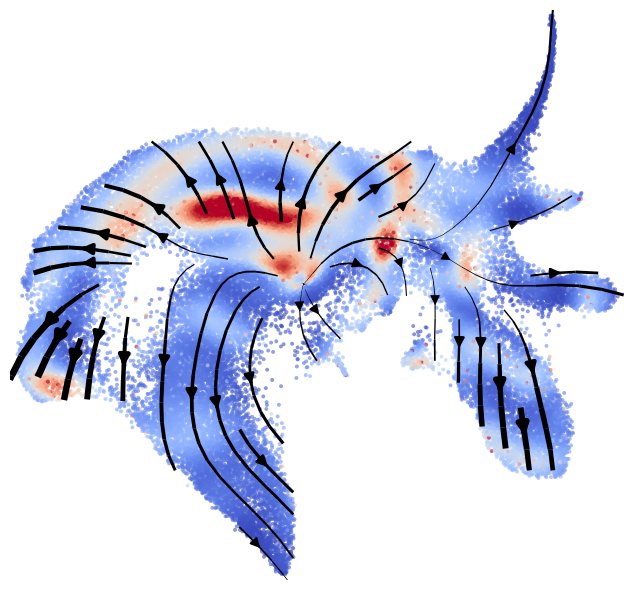

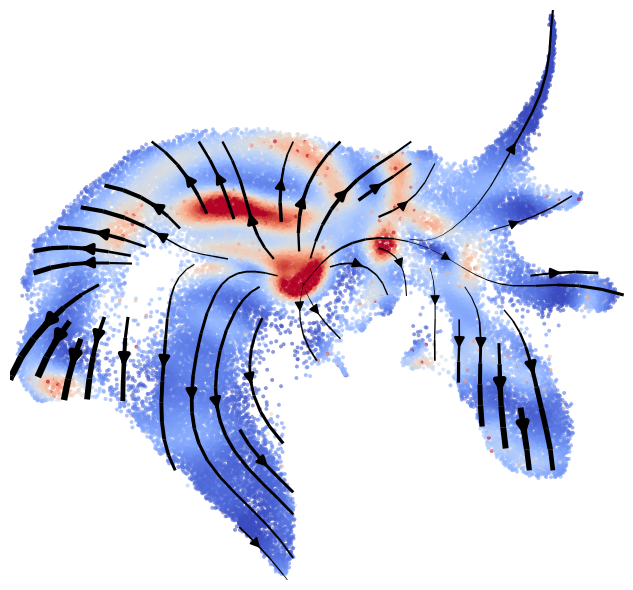

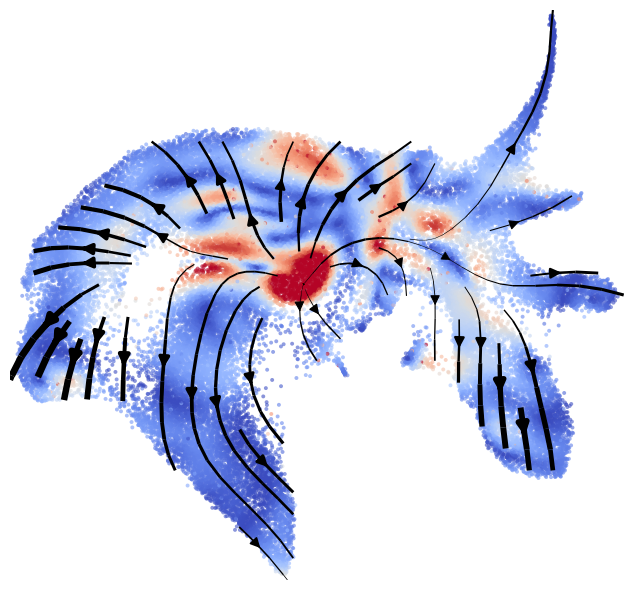

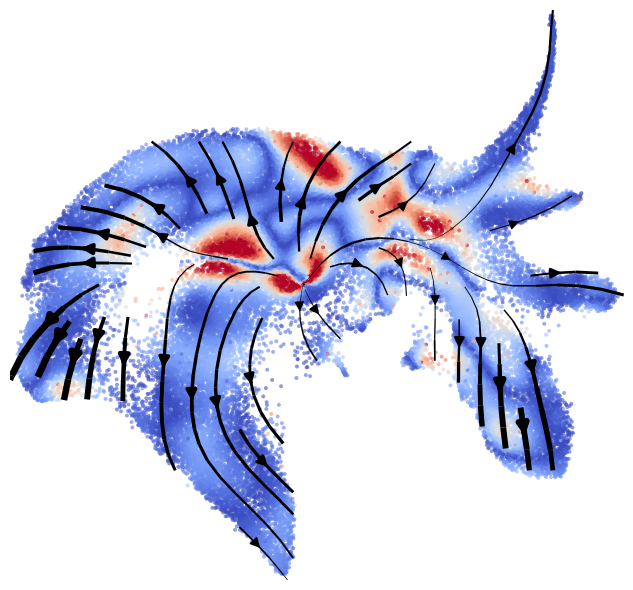

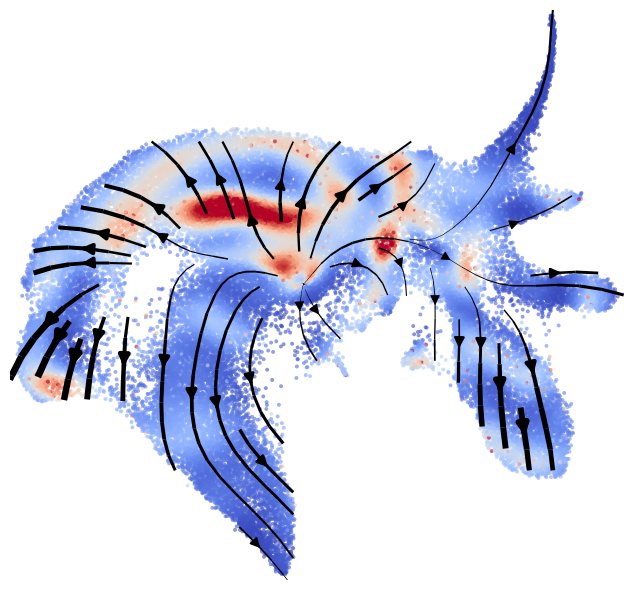

In [32]:
import matplotlib.pyplot as plt
from scripts.FlowCurvature import compute_flow_curvature
from scripts.plotting import *

# ==============================================================
# 0. Compute curvature + acceleration decomposition
# ==============================================================
X_emb = adata_cospar.obsm["X_emb"]
curv = compute_flow_curvature(emb, X_emb)

A        = curv["A"]          # (N, D)
A_tan    = curv["A_tan"]      # (N, d)
A_along  = curv["A_along"]    # (N, D)
A_steer  = curv["A_steer"]    # (N, d)
A_nor    = curv["A_nor"]      # (N, D)

# Raw magnitudes
A_norm        = np.linalg.norm(A, axis=1)
A_tan_norm    = np.linalg.norm(A_tan, axis=1)
A_steer_norm  = np.linalg.norm(A_steer, axis=1)
A_nor_norm    = np.linalg.norm(A_nor,   axis=1)

# ==============================================================
# 1. Quantile clipping helper
# ==============================================================

def clip_quantile(arr, q_low=2, q_high=98):
    lo, hi = np.percentile(arr, [q_low, q_high])
    return np.clip(arr, lo, hi)

speed  = np.linalg.norm(curv["V"], axis=1) + 1e-12
speed2 = speed**2

# curvature-scaled magnitudes
A_curv_norm       = A_norm       / speed2
A_tan_curv_norm   = A_tan_norm   / speed2
A_steer_curv_norm = A_steer_norm / speed2
A_nor_curv_norm   = A_nor_norm   / speed2

# clipped for visualization
A_curv_c       = clip_quantile(A_curv_norm)
A_tan_curv_c   = clip_quantile(A_tan_curv_norm)
A_steer_curv_c = clip_quantile(A_steer_curv_norm)
A_nor_curv_c   = clip_quantile(A_nor_curv_norm)

# ==============================================================
# 2. Plot curvature-scaled components
# ==============================================================

common_kwargs = dict(
    tps_vf=emb.tps_vf,
    stream_density=0.9,
    streamline_thickness=5.0,
    arrowsize=1.5,
    scatter_size=8,
    scatter_alpha=0.6,
    cmap="coolwarm",
    show_axes=False
)

# --- total acceleration curvature ---
plot_velocity_streamplot(
    X_emb,
    scatter_color=A_curv_c,
    **common_kwargs
)

# --- tangent acceleration curvature ---
plot_velocity_streamplot(
    X_emb,
    scatter_color=A_tan_curv_c,
    **common_kwargs
)

# --- steering (geodesic) curvature contribution ---
plot_velocity_streamplot(
    X_emb,
    scatter_color=A_steer_curv_c,
    **common_kwargs
)

# --- normal (extrinsic) curvature contribution ---
plot_velocity_streamplot(
    X_emb,
    scatter_color=A_nor_curv_c,
    **common_kwargs
)

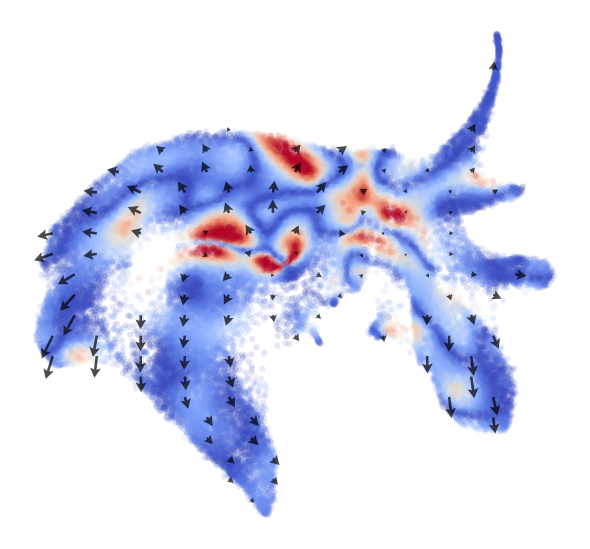

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

from scripts.plotting import compute_velocity_on_grid


# -----------------------------------------------------------------------------
# Helpers
# -----------------------------------------------------------------------------
def points_inside_mask(X, seeds, k=8, radius_scale=1.2):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    r = np.median(nn.kneighbors(X)[0][:, -1]) * radius_scale
    neigh = nn.radius_neighbors(seeds, radius=r, return_distance=False)
    return np.array([len(ix) > 0 for ix in neigh])


# -----------------------------------------------------------------------------
# Data
# -----------------------------------------------------------------------------
curvature = A_steer_curv_c
V_cells = emb.tps_vf.predict(X_emb)


# -----------------------------------------------------------------------------
# Velocity grid (sparse but visible)
# -----------------------------------------------------------------------------
Xg, _, _ = compute_velocity_on_grid(
    X_emb,
    grid_size=25,
    min_mass=0.02
)

keep = points_inside_mask(X_emb, Xg)
Xg = Xg[keep][::2]
Vg = emb.tps_vf.predict(Xg)


# -----------------------------------------------------------------------------
# Plot
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))

# Cells (main signal)
ax.scatter(
    X_emb[:, 0], X_emb[:, 1],
    c=curvature,
    cmap="coolwarm",
    s=20,              # ↓ smaller dots
    alpha=0.15,
    linewidths=0,
    zorder=1
)

# Velocity field (clear but not dominant)
ax.quiver(
    Xg[:, 0], Xg[:, 1],
    Vg[:, 0], Vg[:, 1],
    angles="xy",
    scale_units="xy",
    scale=4.0,
    width=0.0045,      # ↑ thicker shaft (this is the key knob)
    color="k",
    alpha=0.7,         # ↑ a bit darker for print
    headwidth=4.2,
    headlength=3.8,
    headaxislength=3.2,
    zorder=2
)


# -----------------------------------------------------------------------------
# Formatting
# -----------------------------------------------------------------------------
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

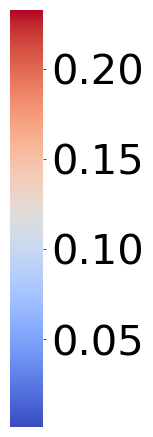

In [34]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

curvature = A_steer_curv_c
norm = Normalize(vmin=curvature.min(), vmax=curvature.max())

fig, ax = plt.subplots(figsize=(1.1, 4.2))  # thinner

cbar = plt.colorbar(
    ScalarMappable(norm=norm, cmap="coolwarm"),
    cax=ax
)

# Remove boundary / outline
cbar.outline.set_visible(False)

# Clean ticks
cbar.ax.tick_params(
    labelsize=30,
    length=2,
    width=0.5
)

plt.tight_layout(pad=0.1)
plt.show()

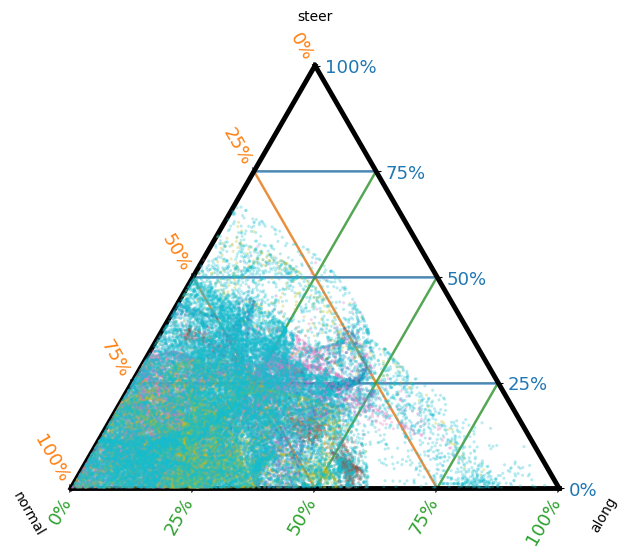

In [35]:
import matplotlib.colors as mcolors
import mpltern

# ==============================================================
# 0. Normalize A by speed**2 (curvature-consistent)
# ==============================================================

V = curv["V"]
speed = np.linalg.norm(V, axis=1) + 1e-12
speed2 = speed**2 + 1e-12

A_rate       = curv["A"]       / speed2[:, None]
A_along_rate = curv["A_along"] / speed2[:, None]
A_steer_rate = curv["A_steer"] / speed2[:, None]
A_nor_rate   = curv["A_nor"]   / speed2[:, None]

# ==============================================================
# 1. Magnitudes and fractions
# ==============================================================

mag_along = np.linalg.norm(A_along_rate, axis=1)
mag_steer = np.linalg.norm(A_steer_rate, axis=1)
mag_nor   = np.linalg.norm(A_nor_rate,   axis=1)

mag_total = mag_along + mag_steer + mag_nor + 1e-12

f_along = mag_along / mag_total
f_steer = mag_steer / mag_total
f_nor   = mag_nor   / mag_total

# Ternary coordinates
t = f_steer * 100
l = f_nor   * 100
r = f_along * 100

# ==============================================================
# 2. Color map
# ==============================================================

labels = np.asarray(adata_cospar.obs["state_info"].values)
uniq = np.unique(labels)
other = [lab for lab in uniq if lab != "Undifferentiated"]

cmap = plt.get_cmap("tab10", len(other))
colmap = {lab: mcolors.to_hex(cmap(i)) for i, lab in enumerate(other)}
colmap["Undifferentiated"] = "#d3d3d3"

# ==============================================================
# 3. Plot
# ==============================================================

fig = plt.figure(figsize=(6.3, 6.1))
ax = fig.add_subplot(1, 1, 1, projection="ternary", ternary_sum=100.0)
ax.set_facecolor("white")

# --- Boundary ---
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(3.5)

    
# --------------------------------------------------------------
# FIRST: scatter Undifferentiated cells (background)
# --------------------------------------------------------------
mask_undiff = labels == "Undifferentiated"
ax.scatter(
    t[mask_undiff], l[mask_undiff], r[mask_undiff],
    color=colmap["Undifferentiated"],
    s=5,
    alpha=0.15,
    edgecolor="none",
    zorder=1
)

# --------------------------------------------------------------
# SECOND: scatter differentiated cells (foreground)
# --------------------------------------------------------------
for lab in uniq:
    if lab == "Undifferentiated":
        continue
    mask = labels == lab
    ax.scatter(
        t[mask], l[mask], r[mask],
        color=colmap[lab],
        s=5,
        alpha=0.3,
        edgecolor="none",
        zorder=10
    )    
# ==============================================================
# Dense, readable grid
# ==============================================================
grid_ticks = [0, 25, 50, 75, 100]

ax.grid(color="0.7", linewidth=1.4)
ax.taxis.set_ticks(grid_ticks)
ax.laxis.set_ticks(grid_ticks)
ax.raxis.set_ticks(grid_ticks)

# ==============================================================
# === AXIS COLOR LINES BLOCK (toggle ON for exploration) =======

for v in [25, 50, 75]:
    ax.axtline(v, color='C0', linewidth=1.8, alpha=0.7)
    ax.axlline(v, color='C1', linewidth=1.8, alpha=0.7)
    ax.axrline(v, color='C2', linewidth=1.8, alpha=0.7)

ax.set_tlabel("steer")
ax.set_llabel("normal")
ax.set_rlabel("along")

ax.taxis.set_ticklabels([f"{v}%" for v in grid_ticks], fontsize=13, color='C0')
ax.laxis.set_ticklabels([f"{v}%" for v in grid_ticks], fontsize=13, color='C1')
ax.raxis.set_ticklabels([f"{v}%" for v in grid_ticks], fontsize=13, color='C2')

# ==============================================================

# --- Clean version: keep colored lines but remove labels ---
# for v in [25, 50, 75]:
#     ax.axtline(v, color='C0', linewidth=2.8, alpha=0.7)
#     ax.axlline(v, color='C1', linewidth=2.8, alpha=0.7)
#     ax.axrline(v, color='C2', linewidth=2.8, alpha=0.7)

# ax.taxis.set_ticklabels([])
# ax.laxis.set_ticklabels([])
# ax.raxis.set_ticklabels([])
# ax.set_tlabel("")
# ax.set_llabel("")
# ax.set_rlabel("")


plt.show()

In [36]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

def grow_clusters(coords, vals, seed_points, k=5, m=0.12):
    """
    Dumb region-growing clusterer on the FULL embedding.
    coords: (N,2)      full embedding
    vals:   (N,)       full curvature/intensity array
    seed_points: (S,2) seed locations in SAME embedding space
    k: neighbors for KNN
    m: threshold (grow into vals > m)
    
    Returns:
        seed_idx_global: indices in full coords
        labels_full:     cluster labels for all N cells
    """
    N = coords.shape[0]

    # --- (1) map seed points to nearest cells in full coords ---
    seed_idx = []
    for p in seed_points:
        d = np.linalg.norm(coords - p, axis=1)
        seed_idx.append(np.argmin(d))
    seed_idx = np.array(seed_idx)

    # --- (2) Build global KNN ---
    nn = NearestNeighbors(n_neighbors=k+1).fit(coords)
    nbr_indices = nn.kneighbors(return_distance=False)[:, 1:]

    # --- (3) Region growing on full data ---
    labels = -np.ones(N, dtype=int)
    stack = []

    for cid, s in enumerate(seed_idx):
        labels[s] = cid
        stack.append(s)

    while stack:
        i = stack.pop()
        cid = labels[i]

        for j in nbr_indices[i]:
            if labels[j] != -1:
                continue
            if vals[j] > m:    # ✔ matching your original logic
                labels[j] = cid
                stack.append(j)

    return seed_idx, labels

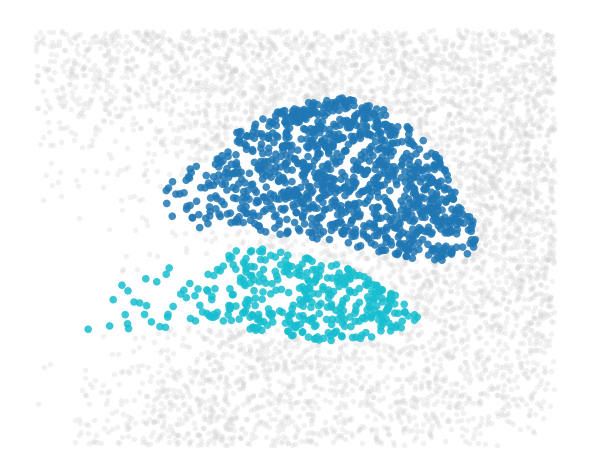

In [37]:
# ---------------------------------------------------------------------
# Base data
# ---------------------------------------------------------------------
coords = X_emb                    # (N, 2)
vals   = A_steer_curv_c               # (N,)

# ---------------------------------------------------------------------
# Zoom window (same as before)
# ---------------------------------------------------------------------
x_min, x_max = -2.5, 2.5
y_min, y_max =  2.5, 6.5

mask_zoom = (
    (coords[:, 0] > x_min) & (coords[:, 0] < x_max) &
    (coords[:, 1] > y_min) & (coords[:, 1] < y_max)
)

# ---------------------------------------------------------------------
# Zoomed data
# ---------------------------------------------------------------------
coords_zoom = coords[mask_zoom]
vals_zoom   = vals[mask_zoom]

# ---------------------------------------------------------------------
# Seed points for cluster growth
# ---------------------------------------------------------------------
seed_points = np.array([
    [0.5,  4.8],
    [-0.3, 4.0],
])

# ---------------------------------------------------------------------
# Run cluster growth on full data
# ---------------------------------------------------------------------
seed_idx_full, labels_grow = grow_clusters(
    coords_zoom,
    vals_zoom,
    seed_points,
    k=5,
    m=0.12
)

# Keep both names available; later cells use labels_grow, this plot uses labels_zoom.
labels_zoom = labels_grow

# Store stable CoSpar-aligned region labels before later cells overwrite mask_zoom.
region2_mask_zoom = mask_zoom.copy()
region2_labels_zoom = labels_zoom.copy()
adata_cospar.obs["cluster"] = np.nan
adata_cospar.obs.loc[region2_mask_zoom, "cluster"] = region2_labels_zoom.astype(str)

fig, ax = plt.subplots(figsize=(6, 6))

mask_assigned = labels_zoom != -1

# Unassigned cells
ax.scatter(
    coords_zoom[~mask_assigned, 0],
    coords_zoom[~mask_assigned, 1],
    c="lightgray",
    s=15,
    alpha=0.3,
    linewidths=0,
    zorder=1
)

# Assigned clusters
ax.scatter(
    coords_zoom[mask_assigned, 0],
    coords_zoom[mask_assigned, 1],
    c=labels_zoom[mask_assigned],
    cmap="tab10",
    s=30,
    alpha=0.85,
    linewidths=0,
    zorder=2
)

ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()



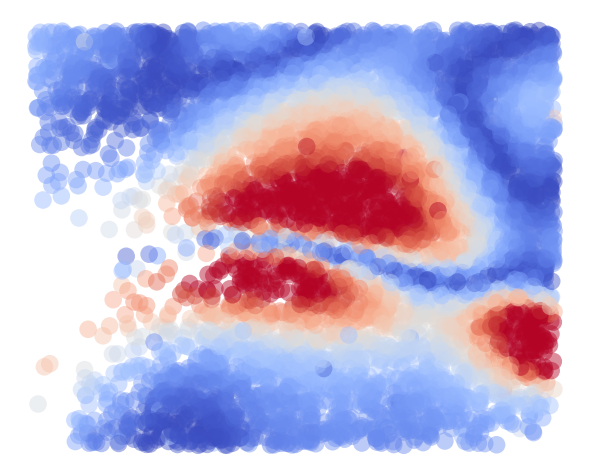

In [38]:
fig, ax = plt.subplots(figsize=(6, 6))

sc = ax.scatter(
    coords_zoom[:, 0],
    coords_zoom[:, 1],
    c=vals_zoom,
    cmap="coolwarm",
    s=160,
    alpha=0.45,
    linewidths=0,
    zorder=1
)

ax.set_aspect("equal")
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

In [39]:
import scanpy as sc
import pandas as pd
import numpy as np

# subset COSPAR AnnData
adata_cospar_zoom = adata_cospar[mask_zoom].copy()
adata_cospar_zoom.obs["cluster"] = labels_grow.astype(str)

adata_cospar_zoom.raw = adata_cospar_zoom
adata_cospar_zoom.obsm["X_umap"] = adata_cospar_zoom.obsm["X_emb"]

# differential expression
cluster_A, cluster_B = "0", "1"

sc.tl.rank_genes_groups(
    adata_cospar_zoom,
    groupby="cluster",
    groups=[cluster_A],
    reference=cluster_B,
    method="wilcoxon",
)

print(adata_cospar_zoom.obs["cluster"].value_counts(), "\n")

# collect DE results
de = adata_cospar_zoom.uns["rank_genes_groups"]

deg_df = (
    pd.DataFrame({
        "gene": de["names"][cluster_A],
        "score": de["scores"][cluster_A],
        "logFC": de["logfoldchanges"][cluster_A],
        "pval": de["pvals"][cluster_A],
        "pval_adj": de["pvals_adj"][cluster_A],
    })
    .dropna()
    .sort_values("pval_adj")
)

print(deg_df.head(20))

cluster
-1    4184
0     1051
1      375
Name: count, dtype: int64 

         gene      score      logFC          pval      pval_adj
25288    Ctsc -18.862848  -5.377169  2.304596e-79  5.828093e-75
25287     Lpl -13.919907  -3.632230  4.795314e-44  6.063435e-40
25286    Psap -13.769527  -2.636417  3.887491e-43  3.277026e-39
25285     Vim -12.268218  -2.592244  1.341745e-34  6.786280e-31
0         Mpo  12.283920   3.357952  1.105108e-34  6.786280e-31
25284    Mmp8 -12.026617  -3.463910  2.574956e-33  1.085301e-29
25283    Tpm4 -11.468994  -1.976943  1.888409e-30  6.822280e-27
1       Elane  11.404285   6.401658  3.980326e-30  1.258231e-26
2        Srgn  11.383105  14.450562  5.075960e-30  1.426288e-26
25282    Lyz2 -10.925759  -2.988916  8.681123e-28  2.195369e-24
3       Prtn3  10.744340   3.697706  6.301087e-27  1.448620e-23
25281    Cybb -10.323219  -1.825256  5.533577e-25  1.166155e-21
25280  S100a6 -10.077019  -2.139904  6.981245e-24  1.358067e-20
25279   Sirpa  -9.822199  -1.452412

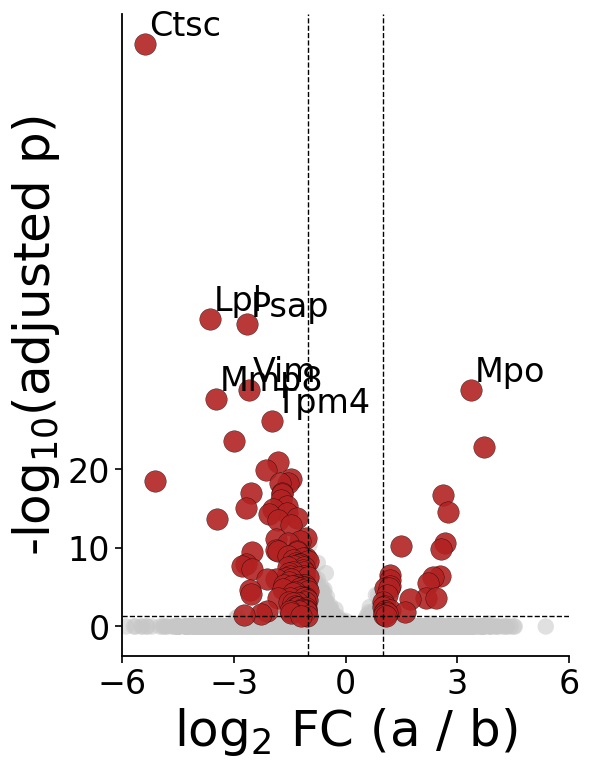

In [40]:
alpha = 0.05
logfc_cut = 1.0

# significance flags
df_clean = deg_df.dropna(subset=["logFC", "pval_adj"]).copy()
df_clean["-log10p"] = -np.log10(df_clean["pval_adj"].clip(lower=1e-300))

sig_both = (df_clean["pval_adj"] < alpha) & (df_clean["logFC"].abs() >= logfc_cut)

# pick top genes (annotation optional)
N_annotate = 7
df_sig_sorted = (
    df_clean.loc[sig_both]
             .sort_values("pval_adj")
             .head(N_annotate)
)

# ------------------------------------------------
# PLOT
# ------------------------------------------------
plt.figure(figsize=(6., 7.8))

# background
plt.scatter(
    df_clean.loc[~sig_both, "logFC"],
    df_clean.loc[~sig_both, "-log10p"],
    s=140, c="#C7C7C7", alpha=0.55, edgecolors="none"
)

# significant points
plt.scatter(
    df_clean.loc[sig_both, "logFC"],
    df_clean.loc[sig_both, "-log10p"],
    s=240, c="#B22222", alpha=0.9,
    edgecolors="black", linewidth=0.25
)

# cutoff lines
plt.axhline(-np.log10(alpha), color="black", linestyle="--", lw=1)
plt.axvline(logfc_cut, color="black", linestyle="--", lw=1)
plt.axvline(-logfc_cut, color="black", linestyle="--", lw=1)

# ------------------------------------------------
# OPTIONAL MANUAL ANNOTATION SECTION
# ------------------------------------------------
for _, row in df_sig_sorted.iterrows():
    plt.text(
        row["logFC"] + 0.10,
        row["-log10p"] + 0.10,
        row["gene"],
        fontsize=24,
        ha="left",
        va="bottom"
    )

# ------------------------------------------------
# Aesthetics
# ------------------------------------------------
ax = plt.gca()

# keep only axis lines
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["bottom", "left"]:
    ax.spines[spine].set_visible(True)
    ax.spines[spine].set_linewidth(1.3)

# axis labels
plt.xlabel(r"log$_2$ FC (a / b)", fontsize=36)
plt.ylabel(r"-log$_{10}$(adjusted p)", fontsize=36)

# ------------------------------------------------
# Ticks: increase size & sparsity
# ------------------------------------------------

# y ticks: 0, 30, 60
yticks = [0, 10, 20]
plt.yticks(yticks, [str(y) for y in yticks], fontsize=24)

# x ticks: spaced, larger
plt.xticks([-6, -3, 0, 3, 6], fontsize=24)

plt.xlim(-6, 6)
plt.grid(False)
plt.tick_params(axis="both", length=5, width=1.2, color="black")

plt.tight_layout()
plt.show()

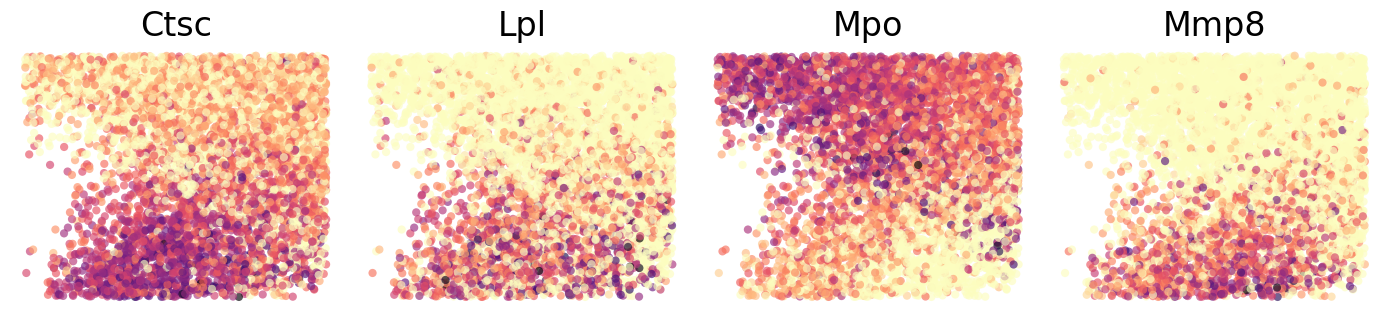

In [41]:
# ----------------------------------------------------------
# FIXED EMBEDDING COORDS
# ----------------------------------------------------------
coords = emb.X_emb   # (N, 2)
X_raw  = emb.X_raw   # (N, G)
gene_names = np.array(emb.gene_names)  # matches X_raw

# ----------------------------------------------------------
# ZOOM REGION
# ----------------------------------------------------------
x_min, x_max = -2.5, 2.5
y_min, y_max =  2.5, 6.5

mask_zoom = (
    (coords[:, 0] > x_min) &
    (coords[:, 0] < x_max) &
    (coords[:, 1] > y_min) &
    (coords[:, 1] < y_max)
)

coords_zoom = coords[mask_zoom]     # (N_zoom, 2)
X_zoom      = X_raw[mask_zoom]      # (N_zoom, G)

# if sparse → dense
if hasattr(X_zoom, "A"):
    X_zoom = X_zoom.A

# ----------------------------------------------------------
# GENES TO PLOT
# ----------------------------------------------------------
genes_to_plot = ["Ctsc", "Lpl", "Mpo", "Mmp8"]

# ----------------------------------------------------------
# 1×4 STRIP FIGURE
# ----------------------------------------------------------
fig, axes = plt.subplots(1, len(genes_to_plot), figsize=(14, 3.2))

for ax, gene in zip(axes, genes_to_plot):

    gi = np.where(gene_names == gene)[0]
    if len(gi) == 0:
        print(f"[Warning] Gene {gene} not found in emb.gene_names.")
        continue
    gi = gi[0]

    vals = X_zoom[:, gi]

    ax.scatter(
        coords_zoom[:, 0],
        coords_zoom[:, 1],
        c=vals,
        cmap="magma_r",
        s=35,
        alpha=0.65,
        edgecolors="none",
    )

    ax.set_title(gene, fontsize=24)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_aspect("equal")

    # remove frame
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.show()

In [42]:
import cospar as cs

selected_fates = ["Neutrophil", "Monocyte"]

cs.tl.fate_map(
    adata_cospar,
    selected_fates=selected_fates,
    source="transition_map",
    map_backward=True
)

cs.tl.fate_bias(
    adata_cospar,
    selected_fates=selected_fates,
    source="transition_map",
    pseudo_count=0,
    sum_fate_prob_thresh=0.1,
)

Results saved at adata.obs['fate_map_transition_map_Neutrophil']
Results saved at adata.obs['fate_map_transition_map_Monocyte']
Results saved at adata.obs['fate_map_transition_map_Neutrophil']
Results saved at adata.obs['fate_map_transition_map_Monocyte']
Results saved at adata.obs['fate_bias_transition_map_Neutrophil*Monocyte']


In [43]:
selected_fates = [
    # ["Neutrophil", "Monocyte"],          # Group A (myeloid)
    # ["Meg", "Erythroid", "Mast", "Baso"], # Group B (erythroid/mast/baso)
    "Neutrophil",
    "Monocyte"
]

cs.tl.progenitor(
    adata_cospar,
    selected_fates=selected_fates,
    source="transition_map",
    map_backward=True,
    bias_threshold_A=0.5,
    bias_threshold_B=0.5,
    sum_fate_prob_thresh=0.2,
    avoid_target_states=True,
)

Results saved at adata.obs['fate_map_transition_map_Neutrophil']
Results saved at adata.obs['fate_map_transition_map_Monocyte']
Results saved at adata.obs['fate_bias_transition_map_Neutrophil*Monocyte']
Results saved at adata.obs[f'progenitor_transition_map_Neutrophil'] and adata.obs[f'diff_trajectory_transition_map_Neutrophil']
Results saved at adata.obs[f'progenitor_transition_map_Monocyte'] and adata.obs[f'diff_trajectory_transition_map_Monocyte']


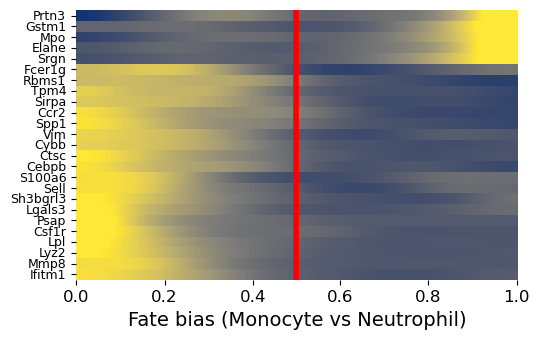

In [44]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.cluster.hierarchy import linkage, leaves_list

# ---------------------------------------------------
# 0. Configuration
# ---------------------------------------------------
genes = (
    deg_df
    .sort_values("pval_adj")
    .head(25)["gene"]
    .tolist()
)

genes = [g for g in genes if g in adata_cospar.var_names]

# === Neutrophil vs Monocyte ===
bias_key = "fate_bias_transition_map_Neutrophil*Monocyte"
prog_A = "progenitor_transition_map_Neutrophil"
prog_B = "progenitor_transition_map_Monocyte"

eps = 1e-6
n_grid = 300          # resolution of continuous axis
sigma = 30            # smoothing strength

# ---------------------------------------------------
# 1. Progenitor UNION mask
# ---------------------------------------------------
prog_mask = (
    adata_cospar.obs[prog_A].values.astype(bool)
    | adata_cospar.obs[prog_B].values.astype(bool)
)

# ---------------------------------------------------
# 2. Extract bias + expression
# ---------------------------------------------------
bias = adata_cospar.obs[bias_key].values[prog_mask]

valid = np.abs(bias - 0.5) > eps
bias = bias[valid]

X = adata_cospar[prog_mask, genes].X
if hasattr(X, "A"):
    X = X.A
X = X[valid]

# ---------------------------------------------------
# 3. Sort by fate bias
# ---------------------------------------------------
order = np.argsort(bias)
bias = bias[order]
X = X[order]

# ---------------------------------------------------
# 4. Smooth expression along fate bias
# ---------------------------------------------------
bias_grid = np.linspace(0, 1, n_grid)
X_smooth = np.zeros((len(genes), n_grid))

for gi in range(len(genes)):
    X_interp = np.interp(bias_grid, bias, X[:, gi])
    X_smooth[gi] = gaussian_filter1d(X_interp, sigma=sigma)

# ---------------------------------------------------
# 5. Z-score per gene (row-wise)
# ---------------------------------------------------
mean = X_smooth.mean(axis=1, keepdims=True)
std = X_smooth.std(axis=1, keepdims=True) + 1e-8
Xz = (X_smooth - mean) / std
Xz = np.clip(Xz, -2, 2)

Z = linkage(Xz, method="average", metric="euclidean")
row_order = leaves_list(Z)

Xz_ord = Xz[row_order]
genes_ord = [genes[i] for i in row_order]

# ---------------------------------------------------
# 6. Plot
# ---------------------------------------------------
fig, ax = plt.subplots(figsize=(5.5, 3.5))

sns.heatmap(
    Xz_ord,
    ax=ax,
    cmap="cividis",
    center=0,
    yticklabels=genes_ord,
    xticklabels=False,
    cbar=False,
    rasterized=True
)

# ---------------------------------------------------
# Fate-bias boundary
# ---------------------------------------------------
boundary_idx = np.argmin(np.abs(bias_grid - 0.5))
ax.axvline(boundary_idx, color="red", linewidth=4)

# ---------------------------------------------------
# X-axis ticks (fate bias)
# ---------------------------------------------------
target_ticks = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
tick_pos = [np.argmin(np.abs(bias_grid - t)) for t in target_ticks]

ax.set_xticks(tick_pos)
ax.set_xticklabels([f"{t:.1f}" for t in target_ticks], fontsize=12)

ax.set_xlabel("Fate bias (Monocyte vs Neutrophil)", fontsize=14)
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()

out_path = "./figures/larry/fate_bias_gene_heatmap_neu_vs_mono.pdf"

fig.savefig(
    out_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02
)

plt.show()

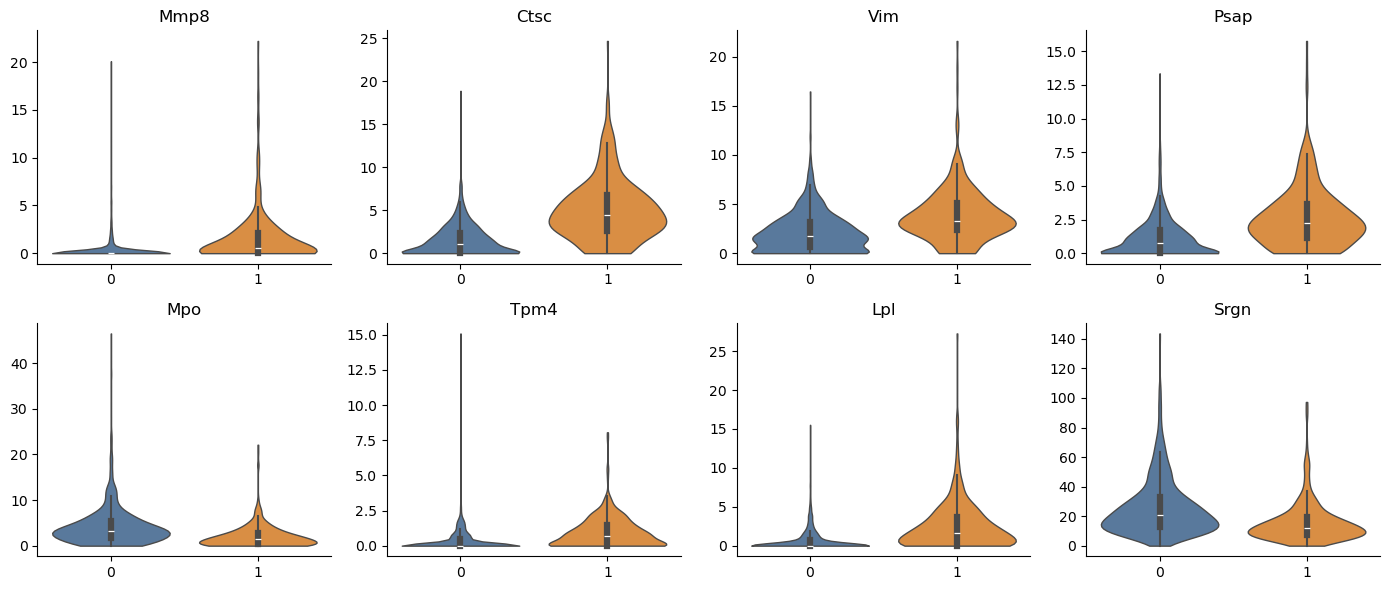

In [45]:
genes = [
    "Mmp8", "Ctsc", "Vim", "Psap",
    "Mpo", "Tpm4", "Lpl", "Srgn"
]

adata_cospar.obs["cluster"] = np.nan
adata_cospar.obs.loc[region2_mask_zoom, "cluster"] = region2_labels_zoom.astype(str)

# keep only clusters 0 and 1
clusters = adata_cospar.obs["cluster"].astype(str).values
mask = (clusters == "0") | (clusters == "1")
adata_sub = adata_cospar[mask]

# extract expression
X = adata_sub.X
if not isinstance(X, np.ndarray):
    X = X.A

clusters_sub = adata_sub.obs["cluster"].astype(str).values

# ---------------------------------------------------
# Build long-form dataframe for seaborn
# ---------------------------------------------------
df_plot = pd.concat([
    pd.DataFrame({
        "gene": g,
        "expression": X[:, np.where(adata_sub.var_names == g)[0][0]],
        "cluster": clusters_sub
    })
    for g in genes
], axis=0)

# ---------------------------------------------------
# Plot: 2 × 4 violin grid
# ---------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey=False)
axes = axes.ravel()

for ax, g in zip(axes, genes):
    sns.violinplot(
        data=df_plot[df_plot["gene"] == g],
        x="cluster",
        y="expression",
        ax=ax,
        cut=0,
        inner="box",
        linewidth=1,
        palette=["#4e79a7", "#f28e2b"],
    )
    ax.set_title(g, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


In [46]:
cs.tl.fate_map(
    adata_cospar,
    selected_fates=["Neutrophil", "Mast", "Meg", "Monocyte", "Baso",   "Erythroid"],
    source="transition_map",
    map_backward=True,
)

Results saved at adata.obs['fate_map_transition_map_Neutrophil']
Results saved at adata.obs['fate_map_transition_map_Mast']
Results saved at adata.obs['fate_map_transition_map_Meg']
Results saved at adata.obs['fate_map_transition_map_Monocyte']
Results saved at adata.obs['fate_map_transition_map_Baso']
Results saved at adata.obs['fate_map_transition_map_Erythroid']


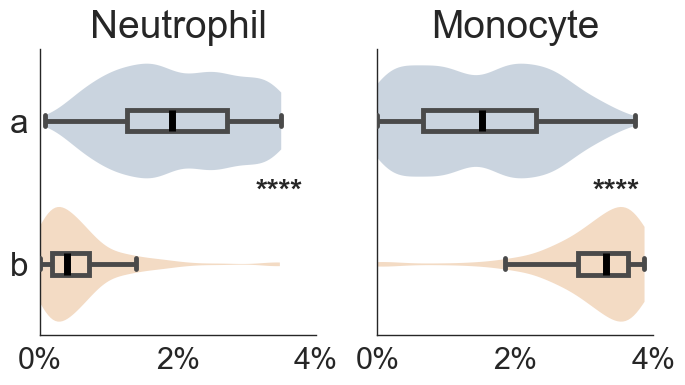

In [47]:
from matplotlib.ticker import FuncFormatter
from scipy.stats import mannwhitneyu
import matplotlib.colors as mcolors
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------
# Helpers (unchanged)
# ---------------------------------------------------
def lighten_color(color, amount=0.6):
    c = np.array(mcolors.to_rgb(color))
    return tuple(c + (1 - c) * amount)

def percent_fmt_sparse(x, _):
    p = x * 100
    if abs(p - 0.5) < 1e-6:
        return "0.5%"
    if abs(p - round(p)) < 1e-6:
        return f"{int(round(p))}%"
    return ""

def p_to_stars(p):
    if p < 1e-4:
        return "****"
    elif p < 1e-3:
        return "***"
    elif p < 1e-2:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

# ---------------------------------------------------
# Configuration (SIMPLIFIED)
# ---------------------------------------------------
cluster_map = {"0": "a", "1": "b"}
palette = {"a": "#4e79a7", "b": "#f28e2b"}

fates = ["Neutrophil", "Monocyte"]

xlim = (0.0, 0.04)
xticks = [0.00, 0.02, 0.04]

# ---------------------------------------------------
# 1. Subset + relabel clusters
# ---------------------------------------------------
clusters = adata_cospar.obs["cluster"].astype(str)
mask = clusters.isin(["0", "1"])
adata_sub = adata_cospar[mask]

# ---------------------------------------------------
# 2. Build long-form dataframe (ONLY 2 FATES)
# ---------------------------------------------------
df_plot = pd.concat([
    pd.DataFrame({
        "fate": fate,
        "probability": adata_sub.obs[f"fate_map_transition_map_{fate}"].values,
        "cluster": adata_sub.obs["cluster"].map(cluster_map).values,
    })
    for fate in fates
], axis=0)

# ---------------------------------------------------
# 3. Plot
# ---------------------------------------------------
sns.set_theme(style="white", context="paper", font_scale=1.2)

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.0, 4.0),
    sharey=True
)

# lighter colors for violins
violin_palette = {
    k: lighten_color(v, amount=0.65)
    for k, v in palette.items()
}

for ax, fate in zip(axes, fates):

    df_f = df_plot[df_plot["fate"] == fate]

    # ---------------- Violin (LIGHT) ----------------
    sns.violinplot(
        data=df_f,
        x="probability",
        y="cluster",
        ax=ax,
        cut=0,
        inner=None,
        linewidth=0,
        palette=violin_palette,
        orient="h",
        alpha=0.9,
        zorder=1,
    )

    # ---------------- Box (STRONG) ----------------
    sns.boxplot(
        data=df_f,
        x="probability",
        y="cluster",
        ax=ax,
        width=0.15,
        showcaps=True,
        boxprops={
            "facecolor": "none",
            "linewidth": 3.5,
        },
        whiskerprops={"linewidth": 3.5},
        capprops={"linewidth": 3.5},
        medianprops={"color": "black", "linewidth": 5.0},
        showfliers=False,
        orient="h",
        palette=palette,
        zorder=3,
    )

    # ---------------- Stats ----------------
    x_a = df_f.loc[df_f["cluster"] == "a", "probability"].dropna()
    x_b = df_f.loc[df_f["cluster"] == "b", "probability"].dropna()

    if len(x_a) >= 3 and len(x_b) >= 3:
        pval = mannwhitneyu(x_a, x_b, alternative="two-sided").pvalue
        stars = p_to_stars(pval)
    else:
        stars = "ns"

    # (optional annotation)
    ax.text(xlim[1] * 0.95, 0.5, stars,
            ha="right", va="center", fontsize=22, fontweight="bold")

    # ---------------- Axis formatting ----------------
    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)
    ax.xaxis.set_major_formatter(FuncFormatter(percent_fmt_sparse))

    ax.set_title(fate, fontsize=28, pad=8)
    ax.tick_params(axis="x", labelsize=22)
    ax.tick_params(axis="y", labelsize=24)

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [48]:
adata_cospar

AnnData object with n_obs × n_vars = 49116 × 25289
    obs: 'time_info', 'state_info', 'NeuMon_fate_bias', 'NeuMon_mask', 'progenitor_Ccr7_DC', 'progenitor_Mast', 'progenitor_Meg', 'progenitor_pDC', 'progenitor_Eos', 'progenitor_Lymphoid', 'progenitor_Erythroid', 'progenitor_Baso', 'progenitor_Neutrophil', 'progenitor_Monocyte', 'sp_500_idx', 'MLPClassifier_predicted_bias', 'growth_rate_raw', 'growth_rate_smooth', 'cluster', 'fate_map_transition_map_Neutrophil', 'fate_map_transition_map_Monocyte', 'fate_bias_transition_map_Neutrophil*Monocyte', 'progenitor_transition_map_Neutrophil', 'diff_trajectory_transition_map_Neutrophil', 'progenitor_transition_map_Monocyte', 'diff_trajectory_transition_map_Monocyte', 'fate_map_transition_map_Mast', 'fate_map_transition_map_Meg', 'fate_map_transition_map_Baso', 'fate_map_transition_map_Erythroid'
    uns: 'Tmap_cell_id_t1', 'Tmap_cell_id_t2', 'available_map', 'clonal_cell_id_t1', 'clonal_cell_id_t2', 'clonal_time_points', 'data_des', 'intraclone_

[TPS ⚠️] Input has 5610 points. This may be slow — consider subsampling ≤ 4000 points.


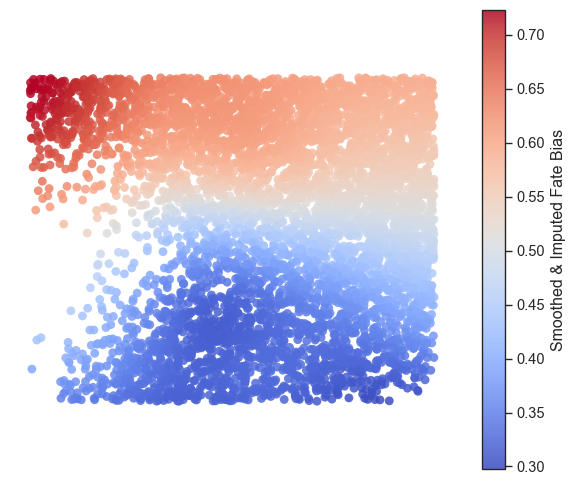

In [49]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

coords = X_emb
vals = A_steer_curv_c

# Use the stable CoSpar-aligned zoom mask from the manual region definition.
mask_zoom = region2_mask_zoom.copy()
coords_zoom = coords[mask_zoom]
vals_zoom = vals[mask_zoom]

if "fate_bias_zoom" in globals():
    bias_raw = fate_bias_zoom
else:
    bias_key = "fate_bias_transition_map_Neutrophil*Monocyte"
    bias_raw = adata_cospar.obs[bias_key].values[mask_zoom]

from scripts.TPS import ThinPlateSpline

# ----------------------------------------------------------
# STEP B — FIT LOCAL TPS MODEL TO SMOOTH FATE BIAS
# ----------------------------------------------------------
valid = ~np.isnan(bias_raw)
coords_fit = coords_zoom[valid]
bias_fit   = bias_raw[valid]

# TPS expects 2D -> 1D mapping, but it handles D>1 fine
tps_local = ThinPlateSpline(coords_fit)
tps_local.fit(bias_fit.reshape(-1,1), dof=20)

# Predict smoothed bias at *all* zoom coords
bias_smooth = tps_local.predict(coords_zoom).ravel()

# ----------------------------------------------------------
# PLOT
# ----------------------------------------------------------

plt.figure(figsize=(6,5))

sc = plt.scatter(
    coords_zoom[:,0],
    coords_zoom[:,1],
    c=bias_smooth,
    cmap="coolwarm",   # high contrast diverging
    s=40,
    alpha=0.85,
    edgecolors="none"
)

plt.colorbar(sc, label="Smoothed & Imputed Fate Bias")

plt.xticks([]); plt.yticks([])
plt.gca().set_frame_on(False)
plt.gca().set_aspect("equal")

plt.tight_layout()
plt.show()


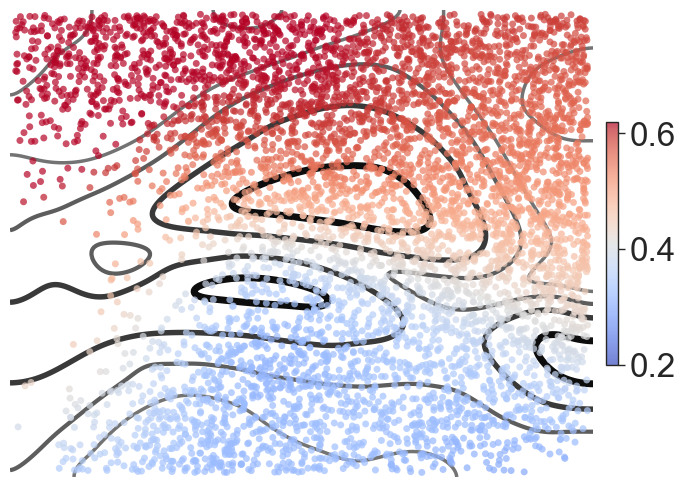

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

# ----------------------------------------------------------
# Data (zoomed)
# ----------------------------------------------------------
x = coords_zoom[:, 0]
y = coords_zoom[:, 1]
vals = A_steer_curv_c
vals_zoom = vals[mask_zoom]
curv = vals_zoom

# ----------------------------------------------------------
# Build grid with small padding
# ----------------------------------------------------------
pad_x = 0.01 * (x.max() - x.min())
pad_y = 0.01 * (y.max() - y.min())

grid_x, grid_y = np.mgrid[
    (x.min() - pad_x):(x.max() + pad_x):300j,
    (y.min() - pad_y):(y.max() + pad_y):300j
]

# --- primary high-quality interpolation ---
curv_grid = griddata(
    np.column_stack((x, y)),
    curv,
    (grid_x, grid_y),
    method="cubic"
)

# --- fallback interpolation for outer region ---
curv_grid_nn = griddata(
    np.column_stack((x, y)),
    curv,
    (grid_x, grid_y),
    method="nearest"
)

# --- merge them: fill NaNs in cubic with NN ---
curv_filled = np.where(np.isfinite(curv_grid), curv_grid, curv_grid_nn)

# --- smooth the filled grid ---
curv_for_plot = gaussian_filter(curv_filled, sigma=8)

# --- contour levels (based on filled field) ---
levels = np.nanpercentile(curv_for_plot, 
                          [25, 50, 75, 95])


# ----------------------------------------------------------
# PLOT
# ----------------------------------------------------------
plt.figure(figsize=(7,6))

ax = plt.gca()

# ----------------------------------------------------------
# Build dynamic linewidth + color based on curvature level
# ----------------------------------------------------------
levels_sorted = np.sort(levels)
norm = (levels_sorted - levels_sorted.min()) / (levels_sorted.max() - levels_sorted.min() + 1e-8)

linewidths = 2.5 + 2.5 * norm

# Darkness scaling (light gray → black)
colors = [(0, 0, 0, 0.55 + 0.4 * n) for n in norm]

# ----------------------------------------------------------
# Draw contour **under** scatter
# ----------------------------------------------------------
CS = ax.contour(
    grid_x, grid_y,
    curv_for_plot,
    levels=levels_sorted,
    colors=colors,
    linewidths=linewidths,
    zorder=1
)

# ----------------------------------------------------------
# Scatter **on top**
# ----------------------------------------------------------
sc = ax.scatter(
    coords_zoom[:,0],
    coords_zoom[:,1],
    c=bias_smooth,
    cmap="coolwarm",
    vmin=0.2,
    vmax=0.62,
    s=25,
    alpha=0.7,
    edgecolor="none",
    zorder=2
)

# ----------------------------------------------------------
# Short colorbar with sparse ticks
# ----------------------------------------------------------
cbar = plt.colorbar(sc, fraction=0.02, pad=0.02)   # shorter colorbar
cbar.set_ticks([0.2, 0.4, 0.6])
cbar.set_ticklabels(["0.2", "0.4", "0.6"], fontsize=24)

# Aesthetics
ax.set_xticks([]); ax.set_yticks([])
ax.set_aspect("equal")
ax.set_frame_on(False)

plt.tight_layout()
plt.show()

In [ ]:
# ------------------------------------------------------
# Gene velocity magnitude scatter for region2
# ------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pathlib import Path
from scipy import sparse

REGION_TAG = "region2"
REGION_A = "0"
REGION_B = "1"
REGION_NAME = {REGION_A: "a", REGION_B: "b"}
ONLY_SCVELO_VELOCITY_GENES = True
DISPLAY_N = 30

out_dir = Path("./figures/larry")
out_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------
# Get stable zoom-region labels and CoSpar indices.
# ------------------------------------------------------
if REGION_TAG == "region2" and "region2_mask_zoom" in globals() and "region2_labels_zoom" in globals():
    zoom_mask_for_velocity = region2_mask_zoom.copy()
    zoom_labels_for_velocity = np.asarray(region2_labels_zoom).astype(str)
elif "adata_cospar_zoom" in globals() and "cluster" in adata_cospar_zoom.obs:
    zoom_mask_for_velocity = mask_zoom.copy()
    zoom_labels_for_velocity = adata_cospar_zoom.obs["cluster"].astype(str).values
elif "labels_grow" in globals() and len(labels_grow) == int(np.sum(mask_zoom)):
    zoom_mask_for_velocity = mask_zoom.copy()
    zoom_labels_for_velocity = np.asarray(labels_grow).astype(str)
elif "labels_zoom" in globals() and len(labels_zoom) == int(np.sum(mask_zoom)):
    zoom_mask_for_velocity = mask_zoom.copy()
    zoom_labels_for_velocity = np.asarray(labels_zoom).astype(str)
else:
    raise NameError("Could not infer zoom-region labels for velocity scatter.")

zoom_cospar_idx = np.where(zoom_mask_for_velocity)[0]
assigned_zoom = np.isin(zoom_labels_for_velocity, [REGION_A, REGION_B])
cospar_idx_ab = zoom_cospar_idx[assigned_zoom]
labels_ab = zoom_labels_for_velocity[assigned_zoom]

print(f"{REGION_TAG} cells in velocity scatter:")
print(pd.Series(labels_ab).map(REGION_NAME).value_counts().rename(index={"a": "region a", "b": "region b"}))

# ------------------------------------------------------
# Map CoSpar cells back to adata rows, where gene velocity lives.
# ------------------------------------------------------
valid_map = mapA2B != -1
cospar_to_adata = pd.Series(
    np.where(valid_map)[0],
    index=mapA2B[valid_map],
    name="adata_idx",
)
cospar_to_adata = cospar_to_adata[~cospar_to_adata.index.duplicated(keep="first")]
matched_adata_idx = cospar_to_adata.reindex(cospar_idx_ab)
has_velocity_match = matched_adata_idx.notna().values

adata_idx_ab = matched_adata_idx.loc[has_velocity_match].astype(int).values
labels_velocity_ab = labels_ab[has_velocity_match]

V_ab = adata.layers["velocity"][adata_idx_ab]
velocity_gene_names = np.asarray(adata.var_names)

print(f"Matched cells with gene velocity: {len(adata_idx_ab)} / {len(cospar_idx_ab)}")
print(pd.Series(labels_velocity_ab).map(REGION_NAME).value_counts().rename(index={"a": "region a", "b": "region b"}))

# ------------------------------------------------------
# Rank genes by region-specific velocity magnitude.
# ------------------------------------------------------
def velocity_region_rank(V_region, gene_names, region_label):
    n_cells = V_region.shape[0]
    if sparse.issparse(V_region):
        mean_abs = np.asarray(abs(V_region).mean(axis=0)).ravel()
        rms = np.sqrt(np.asarray(V_region.power(2).mean(axis=0)).ravel())
        signed_mean = np.asarray(V_region.mean(axis=0)).ravel()
    else:
        V_region = np.asarray(V_region)
        mean_abs = np.mean(np.abs(V_region), axis=0)
        rms = np.sqrt(np.mean(V_region ** 2, axis=0))
        signed_mean = np.mean(V_region, axis=0)

    df = pd.DataFrame({
        "gene": gene_names,
        "region": REGION_NAME[region_label],
        "n_cells": n_cells,
        "mean_abs_velocity": mean_abs,
        "rms_velocity": rms,
        "signed_mean_velocity": signed_mean,
    })

    if ONLY_SCVELO_VELOCITY_GENES and "velocity_genes" in adata.var.columns:
        velocity_gene_mask = adata.var["velocity_genes"].astype(bool).values
        if len(velocity_gene_mask) == len(df):
            df = df.loc[velocity_gene_mask].copy()

    df = df.sort_values("mean_abs_velocity", ascending=False).reset_index(drop=True)
    df.insert(0, "velocity_rank", np.arange(1, len(df) + 1))
    return df

velocity_rank_a = velocity_region_rank(V_ab[labels_velocity_ab == REGION_A], velocity_gene_names, REGION_A)
velocity_rank_b = velocity_region_rank(V_ab[labels_velocity_ab == REGION_B], velocity_gene_names, REGION_B)

vel_ab = (
    velocity_rank_a[["gene", "velocity_rank", "mean_abs_velocity", "rms_velocity"]]
    .rename(columns={
        "velocity_rank": "velocity_rank_a",
        "mean_abs_velocity": "velocity_mag_a",
        "rms_velocity": "rms_velocity_a",
    })
    .merge(
        velocity_rank_b[["gene", "velocity_rank", "mean_abs_velocity", "rms_velocity"]]
        .rename(columns={
            "velocity_rank": "velocity_rank_b",
            "mean_abs_velocity": "velocity_mag_b",
            "rms_velocity": "rms_velocity_b",
        }),
        on="gene",
        how="inner",
    )
)

# ------------------------------------------------------
# Add expression DEG logFC from this notebook's DEG analysis.
# ------------------------------------------------------
deg_for_color = deg_df.copy().reset_index(drop=True)
if "deg_rank" not in deg_for_color.columns:
    deg_for_color.insert(0, "deg_rank", np.arange(1, len(deg_for_color) + 1))

vel_ab = vel_ab.merge(
    deg_for_color[["gene", "deg_rank", "logFC", "pval_adj"]]
    .rename(columns={
        "deg_rank": "deg_rank_a_vs_b",
        "logFC": "deg_logFC_a_vs_b",
        "pval_adj": "deg_pval_adj_a_vs_b",
    }),
    on="gene",
    how="left",
)

vel_ab["velocity_log2_ratio_a_over_b"] = np.log2(
    (vel_ab["velocity_mag_a"] + 1e-12) / (vel_ab["velocity_mag_b"] + 1e-12)
)

selected_scatter_genes = [
    "Npm1", "Set", "C1qbp", "Hspd1",
    "Hspa9", "Elane", "Srgn",
]
selected_vel_ab = vel_ab.loc[vel_ab["gene"].isin(selected_scatter_genes)].copy()
missing_selected = sorted(set(selected_scatter_genes) - set(selected_vel_ab["gene"]))
if missing_selected:
    print("Selected genes not in fitted velocity-gene scatter table:", missing_selected)

# ------------------------------------------------------
# Scatterplot colored by expression DEG logFC.
# ------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.4, 7.0))

plot_df = vel_ab.dropna(subset=["deg_logFC_a_vs_b"]).copy()
missing_logfc = len(vel_ab) - len(plot_df)
if missing_logfc:
    ax.scatter(
        vel_ab.loc[vel_ab["deg_logFC_a_vs_b"].isna(), "velocity_mag_a"],
        vel_ab.loc[vel_ab["deg_logFC_a_vs_b"].isna(), "velocity_mag_b"],
        s=35,
        c="#d0d0d0",
        alpha=0.45,
        linewidths=0,
        zorder=1,
    )
    print(f"Genes without DEG logFC in velocity scatter: {missing_logfc}")

vlim = np.nanpercentile(np.abs(plot_df["deg_logFC_a_vs_b"]), 98)
if not np.isfinite(vlim) or vlim <= 0:
    vlim = 1.0
norm = mcolors.TwoSlopeNorm(vmin=-vlim, vcenter=0.0, vmax=vlim)

sc = ax.scatter(
    plot_df["velocity_mag_a"],
    plot_df["velocity_mag_b"],
    c=plot_df["deg_logFC_a_vs_b"],
    cmap="coolwarm",
    norm=norm,
    s=30,
    alpha=0.5,
    linewidths=0,
    zorder=2,
)

if len(selected_vel_ab) > 0:
    ax.scatter(
        selected_vel_ab["velocity_mag_a"],
        selected_vel_ab["velocity_mag_b"],
        s=220,
        facecolors="none",
        edgecolors="black",
        linewidths=1.8,
        zorder=5,
    )

xy_max = np.nanpercentile(vel_ab[["velocity_mag_a", "velocity_mag_b"]].values, 99.5)
if len(selected_vel_ab) > 0:
    xy_max = max(
        xy_max,
        1.08 * selected_vel_ab[["velocity_mag_a", "velocity_mag_b"]].to_numpy().max(),
    )

ax.plot([0, xy_max], [0, xy_max], color="black", lw=1, ls="--", alpha=0.45)
ax.set_xlim(left=0, right=xy_max)
ax.set_ylim(bottom=0, top=xy_max)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Region a mean absolute gene velocity")
ax.set_ylabel("Region b mean absolute gene velocity")
ax.set_title(f"{REGION_TAG} gene velocity magnitude colored by expression logFC")

cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Expression logFC (region a vs region b)")

plt.tight_layout()
fig.savefig(out_dir / f"{REGION_TAG}_a_vs_b_gene_velocity_magnitude_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


display(
    vel_ab.sort_values("velocity_log2_ratio_a_over_b", ascending=False)
    [[
        "gene", "velocity_mag_a", "velocity_mag_b",
        "velocity_rank_a", "velocity_rank_b",
        "deg_logFC_a_vs_b", "deg_pval_adj_a_vs_b", "velocity_log2_ratio_a_over_b",
    ]]
    .head(DISPLAY_N)
)

